# Jev as a Judge

A doctor's scheduling assistant must turn messages such as “I can work late on Friday”
into the right action. This lab checks whether it understood the request, using Jev and GPT-5.

We compare three approaches: **Jev alone**, **GPT-5 alone**, and **Jev with GPT-5 fallback**.
The notebook makes live API calls and records the verdict, cost and any escalation.

## What are we judging?

The scheduling assistant reads a doctor's message and chooses an action. The judge sees
that message and the predicted action; it does not execute appointments or see the human answer.

**Failure category:** Failure to interpret indirect or underspecified requests.

**Binary question:** Did the router fail to interpret the indirect or underspecified scheduling request?

### The routing policy

| Intent | What the assistant can do |
| --- | --- |
| `LIST_APPOINTMENTS` | View existing appointments; not analyze historical patient counts. |
| `CANCEL_APPOINTMENTS` | Cancel all appointments in a date/time range. |
| `RESCHEDULE_APPOINTMENTS` | Move all appointments from one date/time range to another. |
| `BLOCK_SLOTS` | Make the doctor unavailable. |
| `UNBLOCK_SLOTS` | Restore availability. |
| `UPDATE_SPECIAL_SLOTS` | Add, extend or reduce working hours. |
| `CONVERSATIONAL_GREETING` | Respond to an opening social greeting. |
| `CLOSING_CONVERSATION` | Recognize a closing thanks, acknowledgment or goodbye. |
| `UNSUPPORTED_REQUEST` | A scheduling operation outside these capabilities, or a request whose operation remains unclear. |
| `IRRELEVANT_QUERY` | A request unrelated to the doctor, schedule, patients or hospital. |

Creating an appointment, or canceling/moving a specific appointment identified by patient
name or relative position, is unsupported. Missing a date, time or destination does **not**
make a recognizable supported action unsupported. When wording or missing calendar state
leaves multiple reasonable interpretations, accept a defensible prediction. Do not invent
prior blocks, working hours, or a rule for prioritizing multiple actions.

### The TRUE/FALSE rule

Return **TRUE** only when all three are established:

1. The message expresses the action indirectly, through shorthand or a misspelling, or with incomplete execution details. Ordinary politeness alone is insufficient.
2. The predicted intent is ruled out by every reasonable reading allowed by the policy.
3. The mismatch is a failure to recover that scheduling meaning.

Return **FALSE** when this failure is not established. FALSE includes correct routes,
defensible ambiguity, and different errors such as reversing explicit available/unavailable
wording or crossing an unsupported capability boundary. It does not mean “correct overall.”

Both Jev and GPT-5 receive these rules and the same six worked examples below.

| Doctor's message | Router prediction | Judge | Why |
| --- | --- | --- | --- |
| I can work a half-day this Saturday. | `UNSUPPORTED_REQUEST` | **TRUE** | Working availability is recoverable despite missing hours. |
| I need to reschedule. | `RESCHEDULE_APPOINTMENTS` | **FALSE** | The rescheduling action was correctly recognized. |
| I can work late on the 3rd until 8 PM. | `UNSUPPORTED_REQUEST` | **TRUE** | The implied extension of working hours was missed. |
| I'm not working *this* Saturday. | `UNBLOCK_SLOTS` | **FALSE** | This is an explicit polarity error, a different category. |
| Move my afternoon. | `UNSUPPORTED_REQUEST` | **TRUE** | Recognizable rescheduling shorthand was rejected. |
| Move Mr. Johnson's appointment from Monday to Tuesday. | `UNSUPPORTED_REQUEST` | **FALSE** | Moving a named patient's appointment is unsupported. |

## 1. Connect to the live APIs

Run the cells in order with a TypeSafe API key and an OpenAI API key.
Keys can come from environment variables, Colab Secrets, an ignored `.env`, or hidden input.
Every judge invocation calls the API; running an inference cell again uses the APIs again.
GPT-5 uses medium reasoning effort and a structured Boolean answer with a brief explanation.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# Colab needs a checkout; locally, open this notebook inside the repository.
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    checkout = Path("/content/routing-evals-lab")
    if not checkout.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", "codex/jev-routing-judge",
                        "https://github.com/The-Gen-Academy/Mastering-Agentic-AI-Week4-Session1.git",
                        str(checkout)], check=True)
    os.chdir(checkout)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "pandas", "python-dotenv", "matplotlib"], check=True)

folders = [Path.cwd(), Path("routing_agent_evals"), Path("AI-Evals-Principles/routing_agent_evals")]
LAB = next(folder.resolve() for folder in folders if (folder / "judge_lab.py").exists())
os.chdir(LAB)
sys.path.insert(0, str(LAB))

In [2]:
import pandas as pd
from IPython.display import display
from prompts.llm_as_judge_prompt import (
    FAILURE_CATEGORY, FAILURE_QUESTION, JEV_JUDGE_PROMPT,
    INDIRECT_OR_UNDERSPECIFIED_FAILURE_PROMPT,
)
from judge_lab import (
    load_dataset, request_for, batch, needs_llm, run_cascade, resolved,
    comparison_metrics, always_false, confidence_bands, threshold_sweep, save_json,
)
from notebook_utils import setup_run, save_run

THRESHOLD = 0.70  # Confidence threshold for escalation to GPT-5.
client, RUN = setup_run(LAB, prompts={
    "jev": JEV_JUDGE_PROMPT,
    "llm": INDIRECT_OR_UNDERSPECIFIED_FAILURE_PROMPT,
})

Live models: {'jev': 'jev-1.13.0', 'llm': 'gpt-5-2025-08-07'}
Every judge call sends an API request. Re-running inference cells incurs new usage.


## 2. Load the labeled examples

We use **21 practice cases** to examine confidence thresholds, then **150 different cases**
to evaluate the judges. Separating these steps prevents us from choosing a cutoff and
claiming success on the very same examples. Both sets run automatically in this notebook.

The six worked examples above are excluded from scoring. Human TRUE/FALSE labels are
used to calculate results; neither judge receives them in its input.

In [3]:
calibration_rows = load_dataset(LAB / "data", split="calibration")
rows = load_dataset(LAB / "data", split="validation")
assert {r["id"] for r in calibration_rows}.isdisjoint(r["id"] for r in rows)
display(pd.DataFrame([
    {"purpose": name, "cases": len(part), "TRUE labels": sum(r["human_label"] == "TRUE" for r in part)}
    for name, part in [("Check thresholds", calibration_rows), ("Evaluate judges", rows)]
]))
print("Example sent to both judges:", request_for(rows[0], "jev")["state"])

,purpose,cases,TRUE labels
0,Check thresholds,21,9
1,Evaluate judges,150,11


Example sent to both judges: {'USER_INPUT': 'Cancel my 10:00 - 10:30 patient Monday', 'final_intent': 'UNSUPPORTED_REQUEST'}


## 3. Set the confidence threshold

We use a confidence threshold of **0.70**: keep a valid Jev verdict at or above it and
ask GPT-5 below it. A higher threshold sends more cases to GPT-5; a lower threshold
keeps more decisions with Jev.

The [CMU Jev-as-a-Judge study](https://arxiv.org/html/2609.26550v5) calibrates this tradeoff
on labeled examples, selecting a threshold that accepts more Jev decisions while keeping
accuracy close to the LLM fallback. The table below compares thresholds on our 21 practice
cases, alongside failure recall, false alarms, and estimated cost. Its `within_2pp_bound`
column checks whether estimated accuracy loss stays within two percentage points using
a one-sided 95% confidence bound.

For binary Choice, `confidence = 2 × winning-label probability − 1`, so confidence
**0.70** corresponds to probability **0.85**. The paper uses winning probability; use this
conversion when comparing thresholds. [TypeSafe's definition](https://docs.typesafe.ai/confidence).


In [4]:
jev_practice = batch(calibration_rows, lambda row: client.call(row, "jev"))
llm_practice = batch(calibration_rows, lambda row: client.call(row, "llm"))
# Compare native-confidence cutoffs on the practice cases.
calibration = threshold_sweep(calibration_rows, jev_practice, llm_practice,
                              thresholds=[0.0, 0.2, 0.4, 0.6, 0.7, 0.8, 0.9, 0.98, 1.0])
threshold_table = pd.DataFrame(calibration).rename(columns={"noninferiority_pass": "within_2pp_bound"})
display(threshold_table[["threshold", "accepted_fraction", "cascade_accuracy", "precision_TRUE",
                         "recall_TRUE", "FP", "FN", "cost_savings_fraction", "within_2pp_bound", "status"]].round(4))
save_json(RUN / "threshold_diagnostics.json", calibration)
print("Cutoff used for evaluation:", THRESHOLD)

,threshold,accepted_fraction,cascade_accuracy,precision_TRUE,recall_TRUE,FP,FN,cost_savings_fraction,within_2pp_bound,status
0,0.00,1.0000,0.7143,0.8000,0.4444,1,5,0.9892,False,below_margin
1,0.20,0.5714,0.7619,0.8333,0.5556,1,4,0.3885,True,meets_margin
2,0.40,0.4762,0.7619,0.8333,0.5556,1,4,0.2949,True,meets_margin
3,0.60,0.3333,0.7619,0.8333,0.5556,1,4,0.1889,True,meets_margin
4,0.70,0.3333,0.7619,0.8333,0.5556,1,4,0.1889,True,meets_margin
5,0.80,0.3333,0.7619,0.8333,0.5556,1,4,0.1889,True,meets_margin
6,0.90,0.1905,0.7619,0.8333,0.5556,1,4,0.0826,True,meets_margin
7,0.98,0.1429,0.7619,0.8333,0.5556,1,4,0.0510,True,meets_margin
8,1.00,0.1429,0.7619,0.8333,0.5556,1,4,0.0510,True,meets_margin


Cutoff used for evaluation: 0.7


## 4. Run Jev, then ask GPT-5 when needed

**Jev call → validate output → confidence gate → GPT-5 fallback → final verdict → logging.**

Keep a valid Jev answer at native confidence **0.70 or above**, for either TRUE or FALSE.
Below the cutoff, or when Jev's output is invalid, ask GPT-5 the same question with the
same policy and evidence. GPT-5 sees no Jev answer or confidence. If fallback fails too,
record an unresolved verdict instead of inventing TRUE or FALSE.

In [5]:
jev = batch(rows, lambda row: client.call(row, "jev"))
example_id = rows[0]["id"]
display(pd.DataFrame([jev[example_id]]).reindex(columns=["label", "confidence", "probabilities", "error"]))

,label,confidence,probabilities,error
0,FALSE,0.92,"{'TRUE': 0.04, 'FALSE': 0.96}",None


In [6]:
before_fallback = client.new_requests
cascade = run_cascade(rows, client, THRESHOLD, jev=jev)
escalated_ids = {r["id"] for r in rows if needs_llm(jev[r["id"]], THRESHOLD)}
assert {key for key, value in cascade.items() if value["route"] == "LLM"} == escalated_ids
print(f"GPT-5 fallback used for {len(escalated_ids)}/{len(rows)} cases.")
print("Live HTTP attempts during fallback:", client.new_requests - before_fallback)

GPT-5 fallback used for 19/150 cases.
Live HTTP attempts during fallback: 19


## 5. Run GPT-5 alone

This is a separate live baseline: GPT-5 judges every evaluation case, including cases
that already went through fallback. It receives the same question, policy, examples
and structured output format. Responses are not reused from the fallback run.

In [7]:
before_baseline = client.new_requests
llm = batch(rows, lambda row: client.call(row, "llm"))
print("GPT-5 baseline HTTP attempts:", client.new_requests - before_baseline)
display(pd.DataFrame([llm[example_id]]).reindex(columns=["label", "reason", "error"]))

GPT-5 baseline HTTP attempts: 150


,label,reason,error
0,FALSE,“Cancel my 10:00 - 10:30 patient Monday” targe...,None


## 6. Compare cost and accuracy

The table and chart compare **Jev**, **GPT-5**, and **Jev with GPT-5 fallback** on the
same evaluation cases. Accuracy is agreement with the reference labels; failure recall
is the share of labeled failures the judge detects. Quality scores use the cases
successfully judged by every approach, with coverage and unresolved counts shown below.

Each cost covers one approach on all **150 evaluation inputs**. Jev's cost includes
its 150 calls; GPT-5's includes its 150 baseline calls; the cascade includes all Jev calls
plus the GPT-5 fallbacks. Costs use recorded token usage and the run's saved prices when
the provider does not report a charge. Missing costs remain unknown. Savings are relative
to GPT-5 alone; practice calls are excluded from this comparison.

The experiment total at the bottom also includes practice calls and running the separate
GPT-5 baseline. It covers these completed results; rerunning inference cells adds usage.


**Cost and accuracy on 150 evaluation cases** (150 cases scored by every approach).

,Accuracy,Failure recall,Estimated cost (USD),Savings vs GPT-5
Approach,,,,
Jev,93.3%,45.5%,$0.0136,98.5%
GPT-5,94.7%,63.6%,$0.9187,0.0%
Jev + GPT-5,94.7%,63.6%,$0.2188,76.2%


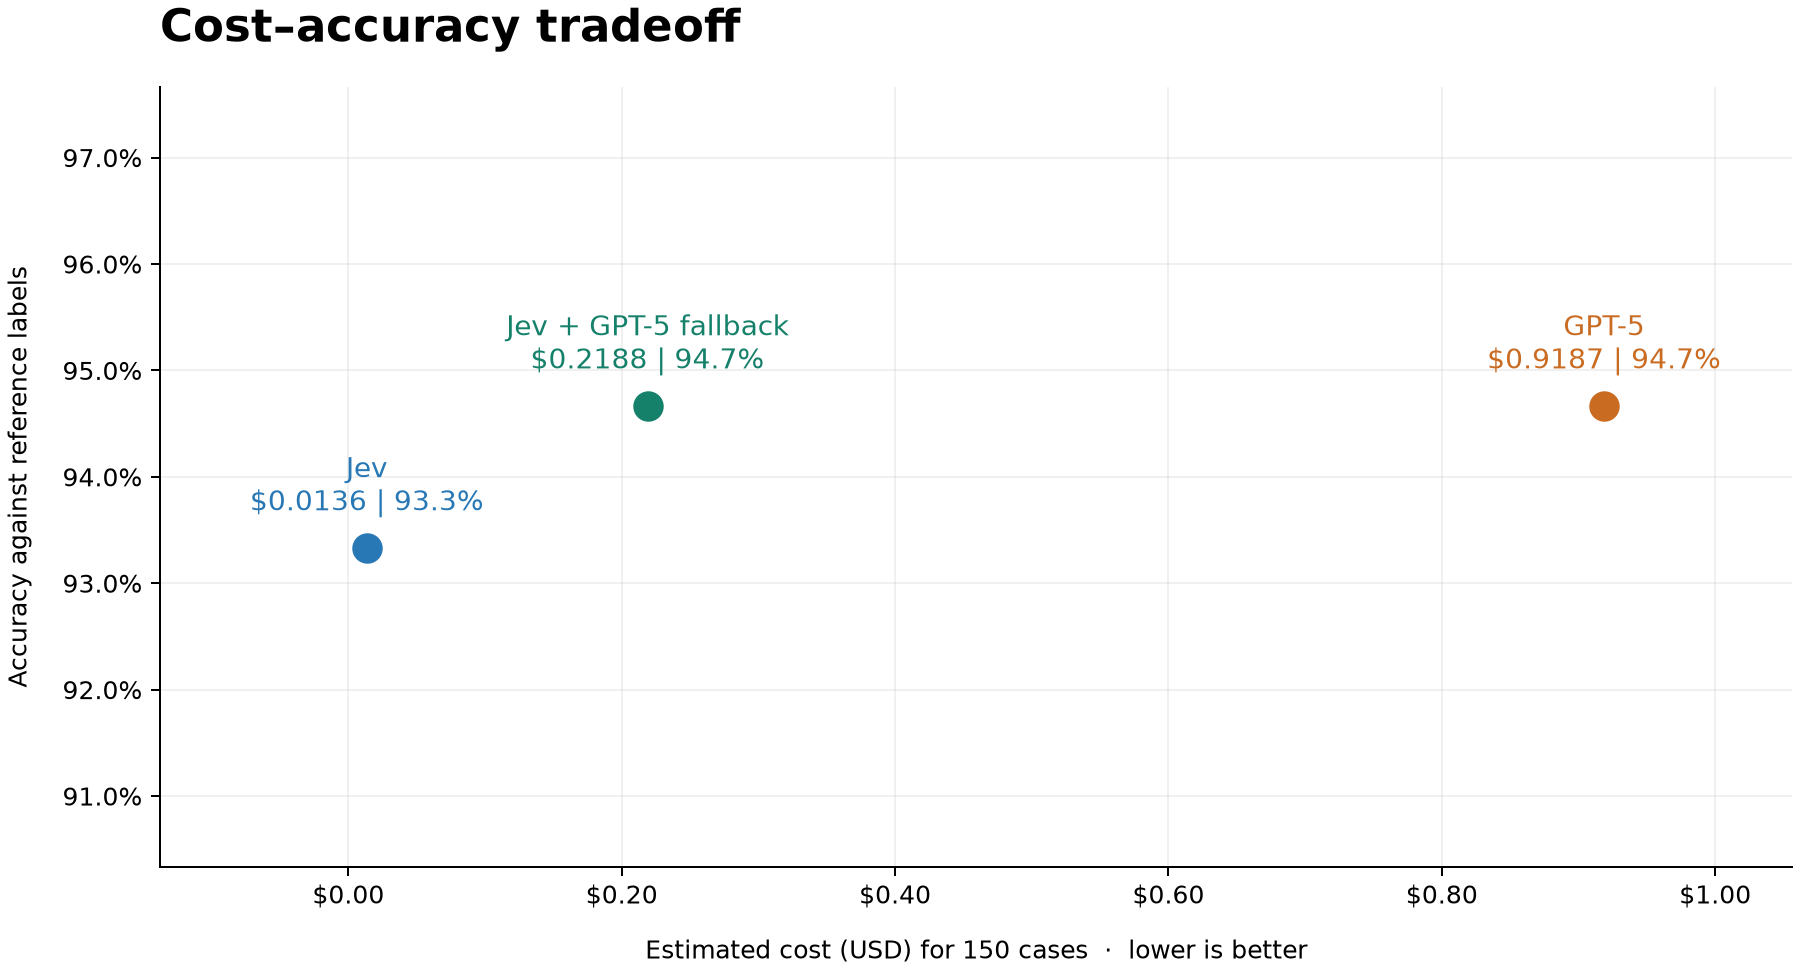

**Jev with GPT-5 fallback achieved the same measured accuracy as GPT-5 (94.7%) at 76.2% lower cost** on this run, using GPT-5 for 19/150 cases.

Jev alone agreed with 140/150 reference labels and detected 5/11 labeled failures. The cascade agreed with 142/150 and detected 7/11 failures.

**Failure detection and coverage**

,Failure precision,Found,False alarms,Missed,Coverage,Unresolved
method,,,,,,
Always FALSE,0.0%,0,0,11,100%,0
Jev,55.6%,5,4,6,100%,0
GPT-5,63.6%,7,4,4,100%,0
Jev + GPT-5,63.6%,7,4,4,100%,0


Always answering FALSE gets **92.7% accuracy** but detects **no failures**. Read accuracy alongside failure recall. These results measure agreement with this dataset's provisional labels.

Completed comparison including practice (reported + estimated USD): 1.315195
Attempts with unknown cost: 0


In [8]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, StrMethodFormatter
from IPython.display import Image, Markdown

approaches = {"Always FALSE": always_false(rows), "Jev": jev, "GPT-5": llm, "Jev + GPT-5": cascade}
scored_ids = [r["id"] for r in rows if all(resolved(a[r["id"]]) for a in approaches.values())]
comparison = pd.DataFrame(comparison_metrics(rows, approaches))
comparison["cost_per_1000_USD"] = comparison.cost_usd / len(rows) * 1000
comparison["GPT5_fraction"] = comparison.llm_routes / len(rows)
comparison.loc[comparison.method.eq("GPT-5"), "GPT5_fraction"] = 1.0

# Compare the cost of running each approach on the same evaluation inputs.
tradeoff = comparison.set_index("method").loc[["Jev", "GPT-5", "Jev + GPT-5"]].copy()
tradeoff.loc[tradeoff.unknown_cost_attempts.gt(0), ["cost_usd", "cost_per_1000_USD"]] = float("nan")
baseline_cost = tradeoff.loc["GPT-5", "cost_usd"]
tradeoff["savings_vs_GPT5"] = 1 - tradeoff.cost_usd / baseline_cost if baseline_cost > 0 else float("nan")
cost_label = "Estimated cost (USD)" if tradeoff.estimated_cost_attempts.gt(0).any() else "Reported cost (USD)"
display(Markdown(f"**Cost and accuracy on {len(rows)} evaluation cases** "
                 f"({len(scored_ids)} cases scored by every approach)."))
table = tradeoff[["accuracy", "recall_TRUE", "cost_usd", "savings_vs_GPT5"]].copy()
for column in ("accuracy", "recall_TRUE", "savings_vs_GPT5"):
    table[column] = table[column].map(lambda value: f"{value:.1%}" if pd.notna(value) else "Unknown")
table["cost_usd"] = table.cost_usd.map(lambda value: f"${value:.4f}" if pd.notna(value) else "Unknown")
table = table.rename(columns={"accuracy": "Accuracy", "recall_TRUE": "Failure recall",
                              "cost_usd": cost_label, "savings_vs_GPT5": "Savings vs GPT-5"})
table.index.name = "Approach"
display(table)
tradeoff.to_csv(RUN / "cost_accuracy.csv")

plot_rows = tradeoff.dropna(subset=["cost_usd", "accuracy"])
if not plot_rows.empty:
    colors = {"Jev": "#2878B5", "GPT-5": "#CA6B22", "Jev + GPT-5": "#16816A"}
    names = {"Jev": "Jev", "GPT-5": "GPT-5", "Jev + GPT-5": "Jev + GPT-5 fallback"}
    fig, ax = plt.subplots(figsize=(10, 5.4), layout="constrained")
    for method, result in plot_rows.iterrows():
        ax.scatter(result.cost_usd, result.accuracy * 100, s=125, color=colors[method], zorder=3)
        ax.annotate(f"{names[method]}\n${result.cost_usd:.4f} | {result.accuracy:.1%}",
                    (result.cost_usd, result.accuracy * 100), xytext=(0, 15),
                    textcoords="offset points", ha="center", fontsize=11, color=colors[method])
    ax.set_title("Cost–accuracy tradeoff", loc="left", fontsize=18, fontweight="bold", pad=18)
    ax.set_xlabel(f"{cost_label} for {len(rows)} cases  ·  lower is better", labelpad=12)
    ax.set_ylabel("Accuracy against reference labels", labelpad=12)
    ax.xaxis.set_major_formatter(StrMethodFormatter("${x:.2f}"))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    max_cost = max(float(plot_rows.cost_usd.max()), 0.001)
    ax.set_xlim(-0.15 * max_cost, max_cost * 1.15)
    min_accuracy = float(plot_rows.accuracy.min()) * 100
    max_accuracy = float(plot_rows.accuracy.max()) * 100
    ax.set_ylim(max(0, min_accuracy - 3), min(102, max_accuracy + 3))
    ax.grid(axis="both", alpha=0.18)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(RUN / "cost_accuracy_tradeoff.png", dpi=180, facecolor="white")
    plt.close(fig)
    display(Image(filename=str(RUN / "cost_accuracy_tradeoff.png")))

j, g, c = (tradeoff.loc[name] for name in ("Jev", "GPT-5", "Jev + GPT-5"))
if pd.notna(c.accuracy) and pd.notna(g.accuracy) and pd.notna(c.savings_vs_GPT5):
    accuracy_comparison = (f"the same measured accuracy as GPT-5 ({c.accuracy:.1%})"
                          if abs(c.accuracy - g.accuracy) < 1e-12 else
                          f"{c.accuracy:.1%} accuracy versus GPT-5's {g.accuracy:.1%}")
    cost_comparison = (f"{c.savings_vs_GPT5:.1%} lower cost" if c.savings_vs_GPT5 >= 0 else
                       f"{-c.savings_vs_GPT5:.1%} higher cost")
    display(Markdown(f"**Jev with GPT-5 fallback achieved {accuracy_comparison} at {cost_comparison}** "
                     f"on this run, using GPT-5 for {int(c.llm_routes)}/{len(rows)} cases."))
if pd.notna(j.accuracy) and pd.notna(c.accuracy):
    display(Markdown(f"Jev alone agreed with {int(j.TP + j.TN)}/{len(scored_ids)} reference labels "
                     f"and detected {int(j.TP)}/{int(j.scored_positive_references)} labeled failures. "
                     f"The cascade agreed with {int(c.TP + c.TN)}/{len(scored_ids)} and detected "
                     f"{int(c.TP)}/{int(c.scored_positive_references)} failures."))

# Keep the class imbalance, false alarms, and missing answers visible.
display(Markdown("**Failure detection and coverage**"))
quality = comparison.set_index("method")[["precision_TRUE", "TP", "FP", "FN", "coverage", "unresolved"]].copy()
quality["precision_TRUE"] = quality.precision_TRUE.map(lambda value: f"{value:.1%}" if pd.notna(value) else "Unknown")
quality["coverage"] = quality.coverage.map(lambda value: f"{value:.0%}")
display(quality.rename(columns={"precision_TRUE": "Failure precision", "TP": "Found", "FP": "False alarms",
                                "FN": "Missed", "coverage": "Coverage", "unresolved": "Unresolved"}))
negative_baseline = comparison.set_index("method").loc["Always FALSE"]
if pd.notna(negative_baseline.accuracy):
    display(Markdown(f"Always answering FALSE gets **{negative_baseline.accuracy:.1%} accuracy** "
                     "but detects **no failures**. Read accuracy alongside failure recall. "
                     "These results measure agreement with this dataset's provisional labels."))

# Account for the completed experiment without counting shared Jev calls twice.
full_cost = sum(r["cost_usd"] for group in (jev_practice, llm_practice, cascade, llm) for r in group.values())
full_unknown = sum(r["unknown_cost_attempts"] for group in (jev_practice, llm_practice, cascade, llm) for r in group.values())
print("Completed comparison including practice (reported + estimated USD):", round(full_cost, 6))
print("Attempts with unknown cost:", full_unknown)


## 7. Inspect errors and save the run

Review the doctor's message, predicted intent, verdict and human label together.
The GPT-5 baseline and fallback are independent calls, so their answers can differ.
Look especially for confident Jev errors that bypass fallback. Labels in this exercise
are provisional; disagreements deserve inspection, not automatic relabeling.

Each API call is logged separately. The decision table records the chosen route,
confidence, final verdict, errors and call IDs. Logs are for inspection and are never
read back to answer later requests.

In [9]:
bands = confidence_bands(rows, jev, llm, THRESHOLD)
display(pd.DataFrame(bands))
records = []
for row in rows:
    case_id = row["id"]
    j, l, final = jev[case_id], llm[case_id], cascade[case_id]
    gate_reason = ("invalid_jev_output" if j.get("error") else
                   "below_confidence_threshold" if case_id in escalated_ids else
                   "confidence_at_or_above_threshold")
    records.append({
        "ID": case_id, "category": FAILURE_CATEGORY, "question": FAILURE_QUESTION,
        "request": row["user_query"], "predicted_intent": row["predicted_intent"],
        "human": row["human_label"], "included_in_paired_scores": case_id in scored_ids,
        "Jev": j["label"], "Jev_confidence": j.get("confidence"), "threshold": THRESHOLD,
        "gate_reason": gate_reason, "route": final["route"], "GPT5_baseline": l["label"],
        "GPT5_baseline_reason": l.get("reason"), "final": final["label"],
        "fallback_reason": final.get("reason") if final["route"] == "LLM" else None,
        "Jev_error": j.get("error"), "GPT5_baseline_error": l.get("error"), "final_error": final.get("error"),
        "Jev_call_id": j["call_id"], "GPT5_baseline_call_id": l["call_id"], "final_call_id": final["call_id"],
        "cascade_cost_usd": final["cost_usd"], "unknown_cost_attempts": final["unknown_cost_attempts"],
    })
review = pd.DataFrame(records)
disagreements = review[review.Jev.ne(review.GPT5_baseline) | review.final.ne(review.human)]
display(disagreements.head(10))
review.to_csv(RUN / "all_results.csv", index=False)
disagreements.to_csv(RUN / "disagreements.csv", index=False)
save_run(client, RUN, rows, THRESHOLD, comparison, bands, scored_ids,
         calibration_rows=calibration_rows, calibration=calibration)
save_json(RUN / "total_usage.json", {"cost_usd": full_cost, "unknown_cost_attempts": full_unknown,
                                    "http_attempts": client.new_requests})

,group,n,paired_n,Jev_unresolved,LLM_unresolved,Jev_accuracy,LLM_accuracy,LLM_fixes,LLM_regressions
0,Kept by Jev,131,131,0,0,0.969466,0.977099,1,0
1,Sent to LLM,19,19,0,0,0.684211,0.736842,4,3


,ID,category,question,request,predicted_intent,human,included_in_paired_scores,Jev,Jev_confidence,threshold,...,final,fallback_reason,Jev_error,GPT5_baseline_error,final_error,Jev_call_id,GPT5_baseline_call_id,final_call_id,cascade_cost_usd,unknown_cost_attempts
4,TEST_086,Failure to interpret indirect or underspecifie...,Did the router fail to interpret the indirect ...,Clear my 3 PM,UNSUPPORTED_REQUEST,TRUE,True,FALSE,0.38,0.7,...,FALSE,'Clear my 3 PM' is shorthand but ambiguous—it ...,None,None,None,c5c06675-9ad6-43ac-9d68-2929abfc7d6a,4541bd93-ba30-44ab-b3f4-86c62cfc2138,9d86b2bd-2e9a-48cc-8f5a-e98b85204d1b,0.013496,0
5,TEST_095,Failure to interpret indirect or underspecifie...,Did the router fail to interpret the indirect ...,Cancel my 3 PM slot,UNSUPPORTED_REQUEST,TRUE,True,FALSE,0.86,0.7,...,FALSE,NaN,None,None,None,4f4b1d0d-f252-4491-bda2-705442eab4aa,ebd7eca2-10b1-48f5-a6f8-21af5a15277a,4f4b1d0d-f252-4491-bda2-705442eab4aa,0.000090,0
7,TEST_129,Failure to interpret indirect or underspecifie...,Did the router fail to interpret the indirect ...,Show me the last week of this month.,IRRELEVANT_QUERY,TRUE,True,TRUE,0.40,0.7,...,TRUE,“Show me the last week of this month” implicit...,None,None,None,fe10db31-9ece-44b2-b0f8-99a955a38b04,9cbb1355-43dd-4dbf-aa89-38d3599271bc,cf9ca9c9-7223-41db-95e3-16ae5ec90897,0.007042,0
8,TEST_148,Failure to interpret indirect or underspecifie...,Did the router fail to interpret the indirect ...,Reserve 10:30 to 11:30 for me tomorrow.,UNSUPPORTED_REQUEST,TRUE,True,FALSE,0.60,0.7,...,TRUE,“Reserve 10:30 to 11:30 for me tomorrow” is re...,None,None,None,ac1fe4e0-6805-4bb3-8852-deee160f42e6,9610833e-54f9-4c29-ac6e-a69aa5d30724,e2d70634-2ac0-4d25-8aca-d3f083f380fa,0.015946,0
9,TEST_211,Failure to interpret indirect or underspecifie...,Did the router fail to interpret the indirect ...,Move my 10 AM appointment to 11 AM.,UNSUPPORTED_REQUEST,TRUE,True,FALSE,0.84,0.7,...,FALSE,NaN,None,None,None,9a613551-e033-4e4a-b1af-a4ae4f8ac4ac,164ba55a-8489-4bde-a51f-9af5c920412f,9a613551-e033-4e4a-b1af-a4ae4f8ac4ac,0.000091,0
21,TEST_235,Failure to interpret indirect or underspecifie...,Did the router fail to interpret the indirect ...,I'm not seeing anyone on Monday.,LIST_APPOINTMENTS,TRUE,True,FALSE,0.04,0.7,...,TRUE,I'm not seeing anyone on Monday implicitly set...,None,None,None,be34abb2-beb1-42ef-b9f2-c0e385ea5696,8faacc8c-3c9e-4674-97f7-6f887a1f6a13,e1d6697f-b868-41c5-b7d8-9f1297419d1f,0.013338,0
24,TEST_276,Failure to interpret indirect or underspecifie...,Did the router fail to interpret the indirect ...,Just show me the 5th.,UNSUPPORTED_REQUEST,TRUE,True,FALSE,0.78,0.7,...,FALSE,NaN,None,None,None,7708db9f-f911-46f5-bc2b-c5bbae6c7c43,7179fa9b-714f-48d5-89f5-aced7d0a8c3f,7708db9f-f911-46f5-bc2b-c5bbae6c7c43,0.000090,0
27,TEST_106,Failure to interpret indirect or underspecifie...,Did the router fail to interpret the indirect ...,I need more breaks,UNSUPPORTED_REQUEST,FALSE,True,FALSE,0.10,0.7,...,FALSE,'I need more breaks' is an indirect request bu...,None,None,None,a86fd2c4-9863-4e25-a707-4c89b993fc0d,11d02848-01df-4b90-8911-421c01537681,74b5f1c1-b98c-42ce-ad1c-ba46cd955663,0.015374,0
29,TEST_255,Failure to interpret indirect or underspecifie...,Did the router fail to interpret the indirect ...,I have an opening on Friday.,UNSUPPORTED_REQUEST,FALSE,True,TRUE,0.02,0.7,...,TRUE,“I have an opening on Friday” indirectly signa...,None,None,None,be9b0386-d7fd-429a-b82e-8c6a11fa96fe,e05fa9d7-5428-45d3-b42c-2b38f5852846,98a7f15f-c13d-4a08-9b25-7c76f2dc4802,0.009547,0
30,TEST_269,Failure to interpret indirect or underspecifie...,Did the router fail to interpret the indirect ...,schedule,IRRELEVANT_QUERY,FALSE,True,TRUE,0.64,0.7,...,TRUE,"'schedule' is an in-domain, underspecified sch...",None,None,None,489ffffc-b55e-41a9-85b7-de81591723b1,e7cee286-0036-479d-93b4-254c73786244,25d9058b-a419-4978-8a6b-392ceae64698,0.007033,0


Completed live HTTP attempts: 361
Outputs: .runs/live-judge/20261028T005457.703224Z
Unresolved cases: {'Always FALSE': 0, 'Jev': 0, 'GPT-5': 0, 'Jev + GPT-5': 0}
